In [45]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import itertools
from scipy.special import beta

sns.set_style("whitegrid")

# 1 - Filter factors
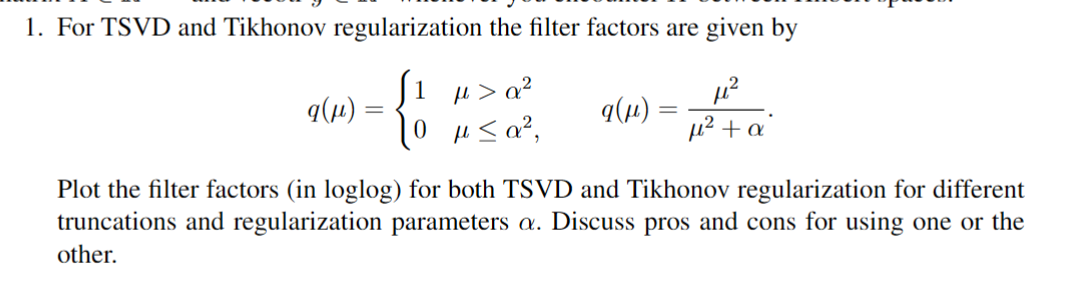

Text(45.347222222222214, 0.5, '$q(μ)$')

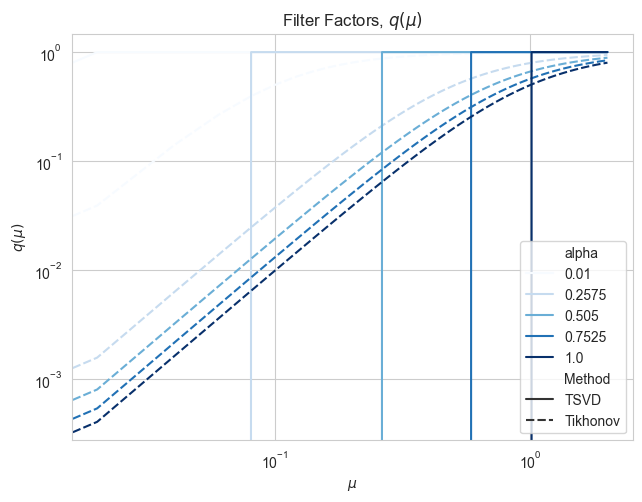

In [7]:
alpha = np.linspace(0.01, 1, 5)
mu = np.linspace(0, 2, 100)

def factor_tsvd(mu, alpha):
    return (mu > alpha**2).astype(float)

def factor_tikhonov(mu, alpha):
    return mu**2 / (mu**2 + alpha)

alphas_grid, mus_grid = np.meshgrid(alpha, mu)

df = pd.DataFrame({
    "alpha": alphas_grid.flatten(),
    "mu": mus_grid.flatten(),
})

df["TSVD"] = factor_tsvd(df["mu"], df["alpha"])
df["Tikhonov"] = factor_tikhonov(df["mu"], df["alpha"])

dfm = pd.melt(df, id_vars=["mu", "alpha"], value_vars=["TSVD", "Tikhonov"], var_name="Method", value_name="Value")


plt.figure()
sns.lineplot(data=dfm, x="mu", y="Value", hue="alpha", style="Method", palette="Blues", legend="full")
plt.tight_layout()
# plt.plot(mu, factor_tsvd(mu), label='TSVD')
# plt.plot(mu, factor_tikhonov(mu), label='Tikhonov')

plt.loglog()
plt.title("Filter Factors, $q(μ)$")
plt.xlabel("$μ$")
plt.ylabel("$q(μ)$")

# 2 - Tikhonov Formulated as a Least Squares Problem
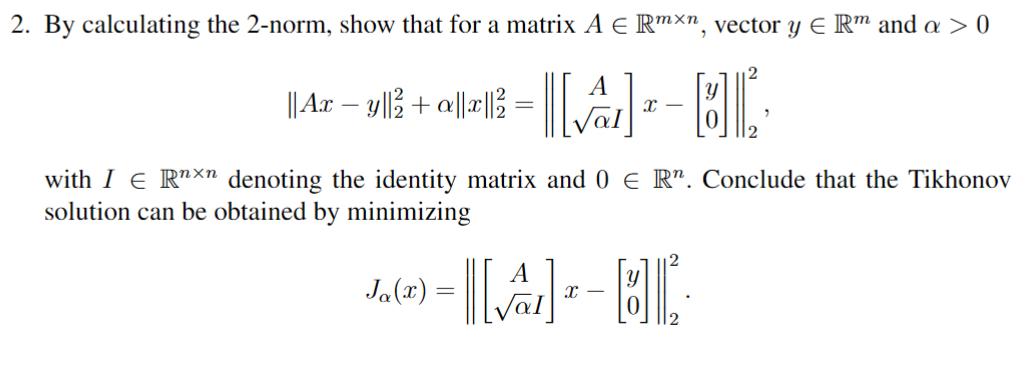
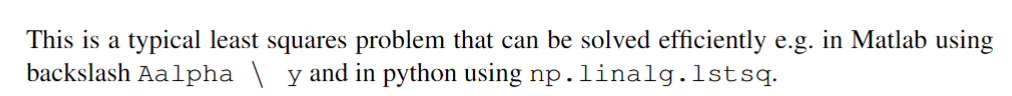

See physical notebook

# 3 - Invertibility of compact operator $K$

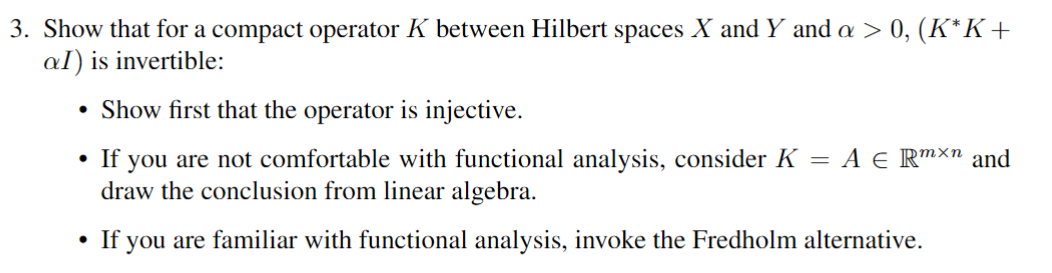

TODO. See physical notebook

# 4 - Regularised Abel Model Problem
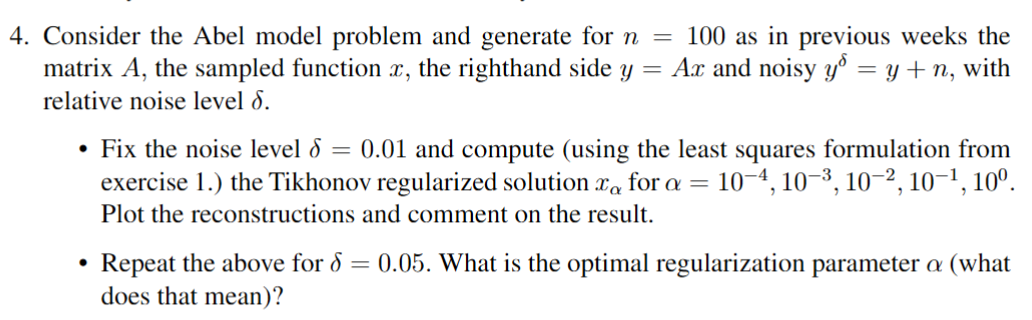

# WHOOPS: I DID THIS FOR THE NUMERICAL DIFF PROBLEM

(100, 1)
(100, 1)
A.shape=(100, 100)
y_vec_noisy_t.shape=(100, 1)
lstsq_a.shape=(200, 100)
lstsq_b.shape=(200, 1)


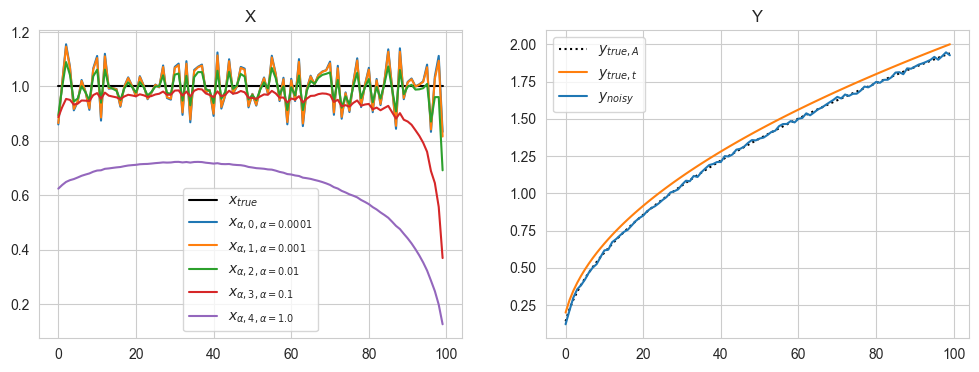

In [74]:
delta = 0.01  # Noise level
alphas = np.asarray([1e-4, 1e-3, 1e-2, 1e-1, 1e0])

# Grid
N = 100 # Number of data points
h = 1 / N
s = np.linspace(0, 1 - h, N)

nu = 0
x = lambda s: s**nu
y = lambda t: t**(nu+1/2)*beta(1+nu,1/2)


# Create s and t vectors with offset to avoid singularity at s = t
svec = np.linspace(h/2, 1 - h/2, N)  # midpoints of intervals
tvec = svec + h/2                    # shifted t values
tvec = tvec.reshape(-1, 1)           # make tvec a column vector

# Create matrices for pairwise differences
sMatrix = np.tile(svec, (N, 1))      # each row is svec
tMatrix = np.tile(tvec, (1, N))      # each column is tvec

# Initialize matrix A
A = np.zeros((N, N))

# Compute entries of A where s < t
index = sMatrix < tMatrix
A[index] = h / np.sqrt(np.abs(tMatrix[index] - sMatrix[index]))

x_vec_true = x(svec)
x_vec_true = x_vec_true.reshape(-1, 1)

y_vec_true_A = A @ x_vec_true
y_vec_true_t = y(tvec)

print(x_vec_true.shape)
print(y_vec_true_t.shape)
# Add noise
noise = delta * np.random.randn(*y_vec_true_A.shape)
y_vec_noisy_A = y_vec_true_A + noise
y_vec_noisy_t = y_vec_true_t + noise

x_vec_recov_naive = np.linalg.solve(A, y_vec_noisy_A)

print(f"{A.shape=}")
print(f"{y_vec_noisy_t.shape=}")

# Solve regularised problem

m, n = A.shape

lstsq_a = np.vstack([A, np.sqrt(alphas[0]) * np.eye(n)])
lstsq_b = np.vstack([y_vec_noisy_t, np.zeros((n, 1))])

print(f"{lstsq_a.shape=}")
print(f"{lstsq_b.shape=}")

x_vec_recov_tikhonov = np.linalg.lstsq(lstsq_a, lstsq_b, rcond=None)[0]

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 4))
ax1.set_title("X")
ax2.set_title("Y")

ax1.plot(x_vec_true, label="$x_{true}$", color="black")
# ax1.plot(x_vec_recov_naive, label="$x_{naive}$")

for i, alpha in enumerate(alphas):
    lstsq_a = np.vstack([A, np.sqrt(alpha) * np.eye(n)])
    lstsq_b = np.vstack([y_vec_noisy_A, np.zeros((n, 1))])

    x_vec_recov_tikhonov = np.linalg.lstsq(lstsq_a, lstsq_b, rcond=None)[0]
    ax1.plot(x_vec_recov_tikhonov, label=f"$x_{{α,{i}, α={alpha} }}$")
ax1.legend()

ax2.plot(y_vec_true_A, label="$y_{true,A}$", ls=":", color="black")
ax2.plot(y_vec_true_t, label="$y_{true,t}$", color="tab:orange")
ax2.plot(y_vec_noisy_A, label="$y_{noisy}$")
ax2.legend()



For $δ=0.01$ It appears that $α=0.01$ or $α=0.001$ have the most faithful reconstructions.

Alpha: 0.001, Distance: 4.896430246959844
Alpha: 0.01, Distance: 0.9407060618546927
Alpha: 0.1, Distance: 1.272646930017248
Alpha: 1.0, Distance: 3.448165656398089


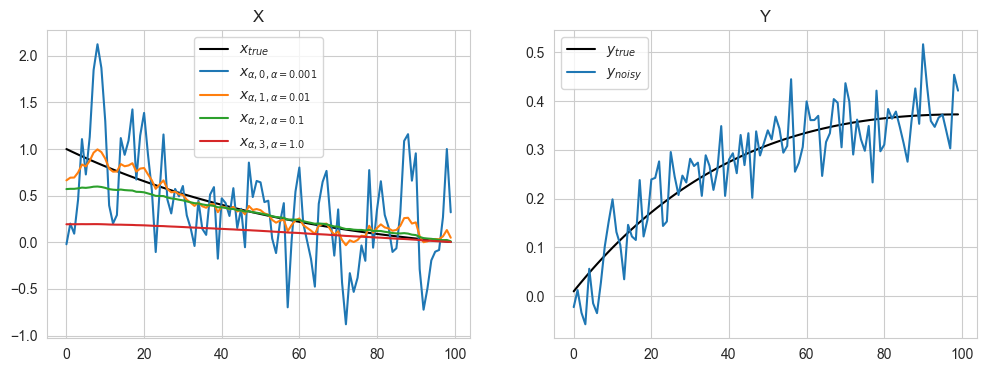

In [42]:
delta = 0.05  # Noise level
alphas = np.asarray([1e-3, 1e-2, 1e-1, 1e0])

# Grid
N = 100 # Number of data points
h = 1 / N
s = np.linspace(0, 1 - h, N)

y = lambda s: s * np.exp(-s)
x = lambda s: np.exp(-s) * (1 - s)

x_vec_true = x(s)

A = np.tril(np.ones((N, N)) * h)
y_vec_true = A @ x_vec_true

# Add noise
noise = delta * np.random.randn(N)
y_vec_noisy = y_vec_true + noise

x_vec_recov_naive = np.linalg.solve(A, y_vec_noisy)

# Solve regularised problem

m, n = A.shape

lstsq_a = np.vstack([A, np.sqrt(alphas[0]) * np.eye(n)])
lstsq_b = np.hstack([y_vec_noisy, np.zeros(n)])

x_vec_recov_tikhonov = np.linalg.lstsq(lstsq_a, lstsq_b, rcond=None)[0]

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 4))
ax1.set_title("X")
ax2.set_title("Y")

ax1.plot(x_vec_true, label="$x_{true}$", color="black")
# ax1.plot(x_vec_recov_naive, label="$x_{naive}$")

for i, alpha in enumerate(alphas):
    lstsq_a = np.vstack([A, np.sqrt(alpha) * np.eye(n)])
    lstsq_b = np.hstack([y_vec_noisy, np.zeros(n)])

    x_vec_recov_tikhonov = np.linalg.lstsq(lstsq_a, lstsq_b, rcond=None)[0]
    distance = np.linalg.norm(x_vec_true - x_vec_recov_tikhonov)
    print(f"Alpha: {alpha}, Distance: {distance}")
    ax1.plot(x_vec_recov_tikhonov, label=f"$x_{{α,{i}, α={alpha} }}$")
ax1.legend()

ax2.plot(y_vec_true, label="$y_{true}$", color="black")
ax2.plot(y_vec_noisy, label="$y_{noisy}$")
ax2.legend()



It appears that $α=0.01$ has the best reconstruction.

We may define the performance using a distance metric such as the $L^2$ distance between the $x_{true}$ and $x_α$.

We observe that this fits with the qualitative assessment: $α=0.01$ has the smallest distance.

Changing the distance metric may influence the optimal choice of the regularisation parameter $α$

# 5 - Tikhonov Reconstruction Formula

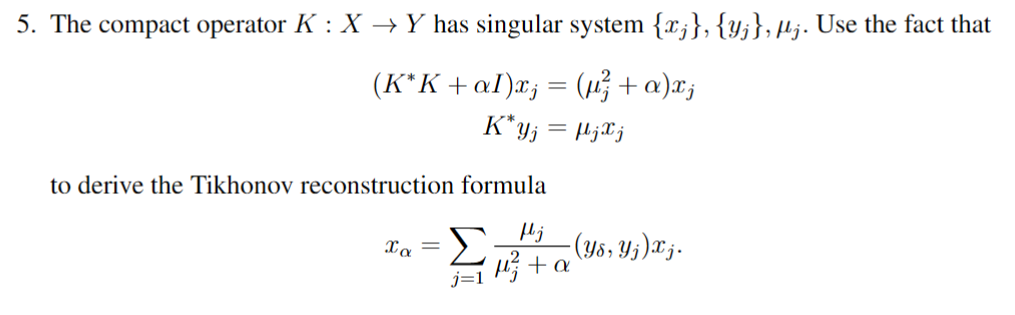

TODO

# 6 - Backwards Heat Problem

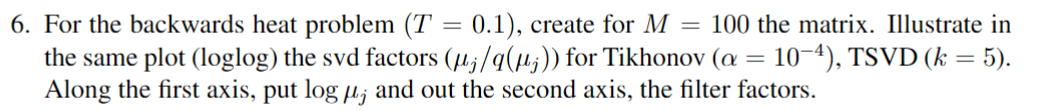

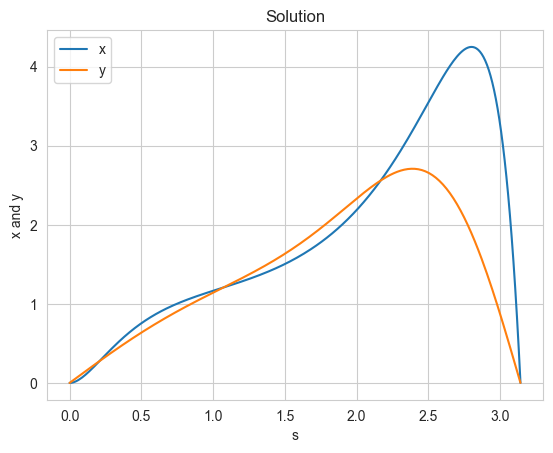

Relative error: 0.7536825252998229


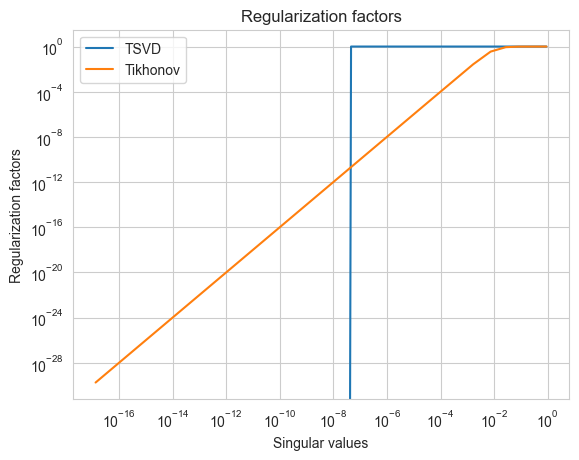

In [85]:
# Parameters


m = 100
L = np.pi  # Length of the interval
N = 2**8   # Number of spatial points
ds = L / N  # Spatial step size
s = np.linspace(0, L, N + 1)  # Spatial grid

# Terminal time
T = 0.1

# Initial condition
u0 = s * np.sin(s) * np.exp((s - np.pi / 2)**2)  # Example initial condition
# u0 = np.sin(m * s)
x0 = u0

# Heat operator function
def HF(x0, T):
    N = len(x0) - 1
    k = np.fft.fftshift(np.arange(-N, N))  # Wave numbers

    # Odd extension to enforce sine series
    x = x0[1:-1]
    x_ext = np.concatenate(([0], x, [0], -x[::-1]))

    # FFT and time evolution
    x_hat = np.fft.fft(x_ext)
    x_hatT = x_hat * np.exp(-k**2 * T)
    xend = np.fft.ifft(x_hatT)

    return np.real(xend[:N+1])

# Compute terminal distribution
y = HF(x0, T)

# Plot
plt.plot(s, x0, label='x')
plt.plot(s, y, label='y')
plt.xlabel('s')
plt.ylabel('x and y')
plt.legend()
plt.title('Solution')
plt.show()

# Error norm - estimate the error against the true solution
error = np.linalg.norm(np.exp(-m**2 * T) * x0 - y) / np.linalg.norm(x0)
print("Relative error:", error)

# Compute matrix A
A = np.zeros((N + 1, N + 1))
Id = np.eye(N + 1)

for kk in range(N):
    A[:, kk] = HF(Id[:, kk], T)

# A is now the matrix representation of the heat operator
U, S, Vh = np.linalg.svd(A)

def factor_tsvd(mu, alpha):
    return (mu > alpha**2).astype(float)

def factor_tikhonov(mu, alpha):
    return mu**2 / (mu**2 + alpha)

alpha = 1e-4

factors_tikhonov = factor_tikhonov(S, alpha)
factors_tsvd = factor_tsvd(S, alpha)

plt.figure()
plt.plot(S, factors_tsvd, label='TSVD')
plt.plot(S, factors_tikhonov, label='Tikhonov')
plt.xlabel('Singular values')
plt.ylabel('Regularization factors')
plt.legend()
plt.title('Regularization factors')
plt.loglog()
plt.show()


# 7 - Philips Model
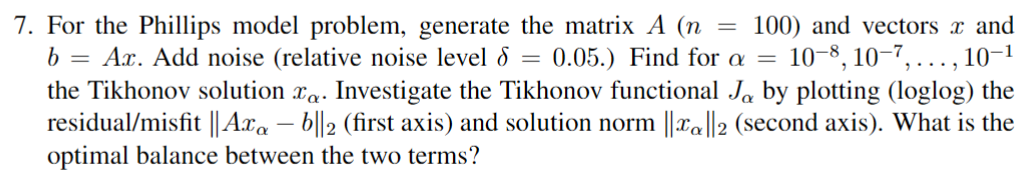

# 8 - Convexity of Tikhonov Functional

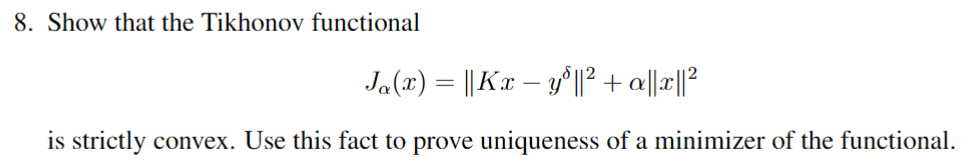

This is trivial having done the optimisation course:
1. Non-negative weighted sums are convexity-preserving
2. Norms are convex